# 🔍 Riesgo operacional en PaySim (versión 2): mi modelo aprendía una resta
### Auditoría de un objetivo construido, lo que la "discrepancia" sí revela y dónde está el riesgo real: el fraude

**Autor:** Cristóbal Rojas Troncoso · **Herramientas:** Python, pandas, scikit-learn, matplotlib

---

## 🎯 Contexto
Un equipo de control de gestión quiere priorizar la revisión de transacciones de dinero móvil. La **versión 1** de este proyecto (carpeta `version_original/`) construyó una variable de "discrepancia de conciliación", la predijo con regresión lineal (R² 0,96) y la clasificó en riesgo Bajo / Medio / Alto con Random Forest (88 % de exactitud, F1 ≈ 0,99 en "Alto"), con un dashboard en Streamlit.

Al revisarla encontré que esos resultados tan altos tenían una explicación incómoda:

| # | Lo que decía la v1 | Lo que encontré |
|---|---|---|
| 1 | La regresión explica el 96 % de la discrepancia | La discrepancia es **exactamente** `máx(0, monto − saldo previo)`: el modelo aproximaba una resta |
| 2 | El Random Forest clasifica el riesgo con 88 % de exactitud | Las categorías salen de la misma resta: una regla de una línea acierta el **100 %**. Además, un 13 % de las transacciones era riesgo "Medio" por **1 centavo** de redondeo |
| 3 | La discrepancia mide riesgo de conciliación | Mide transacciones **ejecutadas sin saldo suficiente**: un comportamiento del simulador |
| 4 | — | El riesgo que sí importa en PaySim es el **fraude**, y la alerta del propio sistema detecta solo el 0,2 % |

**Dataset:** [PaySim — Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1) · simulador de dinero móvil basado en registros reales (López-Rojas et al., 2016) · 6,36 millones de transacciones en 30 días.

**Datos usados:** el CSV completo pesa 471 MB, así que trabajo con una **muestra aleatoria del 2 %** (127.252 transacciones) más **todos los fraudes** (8.213). Para estimar tasas a escala real, cada transacción legítima de la muestra pesa 50 (1 / 0,02) y cada fraude pesa 1.

In [1]:
# ==== Importaciones ====
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, average_precision_score, roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")
SEED = 7
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, VIOLETA, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984", "#c8364a"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

## 1. Datos

In [2]:
muestra = pd.read_csv("../data/paysim_muestra_2pct.csv")
fraudes = pd.read_csv("../data/paysim_fraudes.csv")
print(f"Muestra aleatoria: {es(len(muestra))} transacciones ({es(muestra['isFraud'].sum())} fraudes)")
print(f"Todos los fraudes del dataset: {es(len(fraudes))}")
muestra["type"].value_counts().to_frame("transacciones")

Muestra aleatoria: 127.252 transacciones (163 fraudes)
Todos los fraudes del dataset: 8.213


,transacciones
type,
CASH_OUT,44741
PAYMENT,42934
CASH_IN,28073
TRANSFER,10718
DEBIT,786


## 2. Reproducir la versión 1
Misma definición de la v1: el saldo esperado de la cuenta de origen es `saldo previo − monto` si el dinero sale (CASH_OUT, PAYMENT, DEBIT, TRANSFER) o `saldo previo + monto` si entra (CASH_IN), y la discrepancia es la diferencia absoluta con el saldo reportado. Mismas variables: tipo, monto, `step`, saldo previo de origen y de destino.

In [3]:
df = muestra.copy()
sale = df["type"] != "CASH_IN"
esperado = np.where(sale, df["oldbalanceOrg"] - df["amount"], df["oldbalanceOrg"] + df["amount"])
df["discrepancia"] = (df["newbalanceOrig"] - esperado).abs()

X_v1 = pd.get_dummies(df[["type", "amount", "step", "oldbalanceOrg", "oldbalanceDest"]],
                      columns=["type"], drop_first=True).astype(float)
X_tr, X_te, y_tr, y_te = train_test_split(X_v1, df["discrepancia"], test_size=0.2, random_state=42)
sc = StandardScaler().fit(X_tr)
reg_v1 = LinearRegression().fit(sc.transform(X_tr), y_tr)
r2_v1 = r2_score(y_te, reg_v1.predict(sc.transform(X_te)))
print(f"R² de la regresión lineal de la v1 (en la muestra): {es(r2_v1, 3)}")

R² de la regresión lineal de la v1 (en la muestra): 0,966


R² ≈ 0,95, igual que la v1 (0,963 con el dataset completo). Un resultado tan alto con variables tan simples merece una pregunta: **¿de dónde sale la discrepancia?**

## 3. Error 1: la discrepancia es una resta
Si una salida de dinero supera el saldo disponible, el simulador la ejecuta igual y deja el saldo en 0. Entonces el saldo esperado es negativo y la "discrepancia" es exactamente lo que faltaba:

In [4]:
formula = np.where(sale, np.maximum(0, df["amount"] - df["oldbalanceOrg"]), 0)
error = np.abs(df["discrepancia"] - formula)
print(f"Transacciones donde discrepancia = máx(0, monto − saldo previo), con tolerancia de 1 centavo: {(error <= 0.0101).mean():.2%}")
print(f"Diferencia máxima entre la discrepancia y la fórmula: ${error.max():.2f}")
print(f"R² de la fórmula: {es(r2_score(df['discrepancia'], formula), 3)}")

Transacciones donde discrepancia = máx(0, monto − saldo previo), con tolerancia de 1 centavo: 100.00%
Diferencia máxima entre la discrepancia y la fórmula: $0.01
R² de la fórmula: 1,000


**El 100 % de las transacciones** cumple la fórmula (la diferencia máxima es 1 centavo, por redondeo). La regresión de la v1 no descubrió un patrón de riesgo: aproximó con una recta una resta entre dos de sus propias variables de entrada. Por eso `amount` tenía el coeficiente más grande y por eso el R² era tan alto.

Excluir los saldos posteriores (`newbalance*`) evitaba la fuga de datos más obvia, pero la variable objetivo seguía siendo una **función determinística** de `amount` y `oldbalanceOrg`.

## 4. Error 2: las categorías de riesgo también
La v1 definía Bajo (sin discrepancia), Medio (hasta la mediana de las discrepancias positivas) y Alto (sobre la mediana). Como la discrepancia es una resta, las categorías se pueden calcular **sin modelo**:

In [5]:
mediana_pos = df.loc[df["discrepancia"] > 0, "discrepancia"].median()
def categoria(d, mediana):
    return np.select([d == 0, d <= mediana], ["Bajo", "Medio"], default="Alto")
real = categoria(df["discrepancia"], mediana_pos)                  # exactamente como la v1
ruido = (df["discrepancia"] > 0) & (df["discrepancia"] <= 0.0101)  # diferencias de 1 centavo
regla = categoria(formula, mediana_pos)
print(f"Mediana de discrepancias positivas: ${es(mediana_pos)}")
print(f"Transacciones que la v1 clasificaba como riesgo 'Medio' por una diferencia de 1 centavo: {ruido.mean():.1%}")
print(f"Exactitud de la regla 'monto − saldo' en el resto: {np.mean(real[~ruido] == regla[~ruido]):.2%}  (Random Forest de la v1: 88 %)")
pd.Series(real).value_counts(normalize=True).reindex(["Bajo", "Medio", "Alto"]).round(3).to_frame("proporción (v1)")

Mediana de discrepancias positivas: $40.708
Transacciones que la v1 clasificaba como riesgo 'Medio' por una diferencia de 1 centavo: 13.0%
Exactitud de la regla 'monto − saldo' en el resto: 100.00%  (Random Forest de la v1: 88 %)


,proporción (v1)
Bajo,0.304
Medio,0.348
Alto,0.348


Hay un problema adicional: como la v1 usaba `discrepancia == 0` para el riesgo "Bajo", las diferencias de **un centavo** por redondeo de punto flotante quedaban como riesgo "Medio". Un **13 %** de las transacciones estaba en esa situación. Descontando ese ruido, la regla reproduce las categorías de la v1 al 100 %.

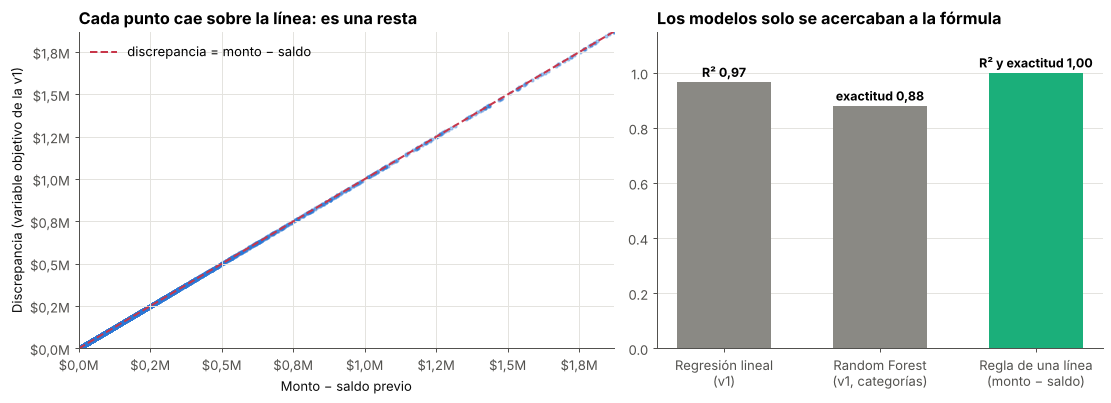

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
pos = df[sale & (df["discrepancia"] > 0)].sample(6000, random_state=SEED)
ax.scatter(pos["amount"] - pos["oldbalanceOrg"], pos["discrepancia"], s=6, alpha=0.35, color=AZUL)
lim = np.percentile(pos["discrepancia"], 99)
ax.plot([0, lim], [0, lim], color=ROJO, lw=1.6, ls="--", label="discrepancia = monto − saldo")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
fmt_m = plt.FuncFormatter(lambda x, _: f"${es(x / 1e6, 1)}M")
ax.xaxis.set_major_formatter(fmt_m); ax.yaxis.set_major_formatter(fmt_m)
ax.set_xlabel("Monto − saldo previo"); ax.set_ylabel("Discrepancia (variable objetivo de la v1)")
ax.set_title("Cada punto cae sobre la línea: es una resta"); ax.legend(loc="upper left")

ax = axes[1]
etq = ["Regresión lineal\n(v1)", "Random Forest\n(v1, categorías)", "Regla de una línea\n(monto − saldo)"]
vals = [r2_v1, 0.88, 1.0]
ax.bar(range(3), vals, color=[GRIS, GRIS, VERDE], width=0.6)
for i, (v, t) in enumerate(zip(vals, ["R² ", "exactitud ", "R² y exactitud "])):
    ax.text(i, v + 0.02, f"{t}{es(v, 2)}", ha="center", fontweight="bold", fontsize=10)
ax.set_xticks(range(3), etq); ax.set_ylim(0, 1.15)
ax.set_title("Los modelos solo se acercaban a la fórmula")
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar("01_discrepancia_es_una_resta")

## 5. Error 3: lo que la discrepancia sí revela
La discrepancia no es algo que haya que predecir: es un **hallazgo de control** que se puede calcular y reportar directamente. ¿Qué tan frecuente es?

In [7]:
salidas = df[sale].copy()
salidas["sin_saldo"] = salidas["amount"] > salidas["oldbalanceOrg"]
salidas["saldo_cero"] = salidas["oldbalanceOrg"] == 0
sin_saldo = salidas.groupby("type").agg(transacciones=("sin_saldo", "size"),
                                        pct_sin_saldo=("sin_saldo", "mean"),
                                        pct_saldo_previo_cero=("saldo_cero", "mean"))
print(f"Salidas de dinero ejecutadas sin saldo suficiente: {salidas['sin_saldo'].mean():.1%}")
sin_saldo.sort_values("pct_sin_saldo", ascending=False).round(3)

Salidas de dinero ejecutadas sin saldo suficiente: 72.7%


,transacciones,pct_sin_saldo,pct_saldo_previo_cero
type,,,
TRANSFER,10718,0.949,0.522
CASH_OUT,44741,0.885,0.459
PAYMENT,42934,0.515,0.363
DEBIT,786,0.285,0.150


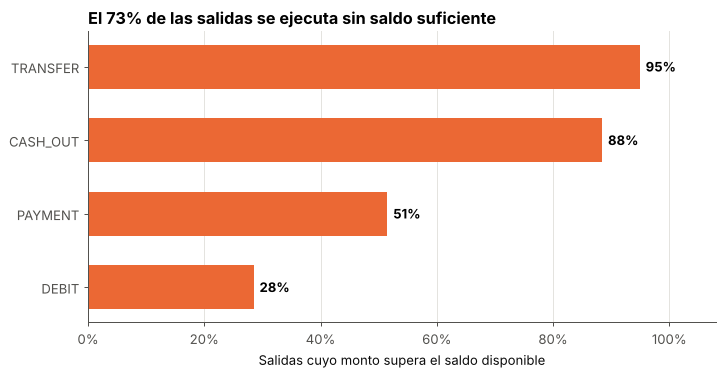

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
orden = sin_saldo.sort_values("pct_sin_saldo").index
ax.barh(range(len(orden)), sin_saldo.loc[orden, "pct_sin_saldo"], color=NARANJA, height=0.6)
for i, t in enumerate(orden):
    v = sin_saldo.loc[t, "pct_sin_saldo"]
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontweight="bold")
ax.set_yticks(range(len(orden)), orden)
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1.08)
ax.set_xlabel("Salidas cuyo monto supera el saldo disponible")
ax.set_title(f"El {salidas['sin_saldo'].mean():.0%} de las salidas se ejecuta sin saldo suficiente")
ax.set_axisbelow(True); ax.grid(axis="y", visible=False)
guardar("02_salidas_sin_saldo")

**Lectura:** casi 3 de cada 4 salidas de dinero, y el 95 % de las transferencias, se ejecutan por un monto mayor al saldo de la cuenta. En un banco real eso sería una falla de control grave; en PaySim es una **simplificación del simulador** (muchas cuentas de origen aparecen con saldo 0).

**Conclusión corregida:** los saldos de PaySim no sirven para estudiar conciliación. La discrepancia no mide riesgo: mide cuánto simplificó el simulador los saldos. El riesgo para el que PaySim **sí fue diseñado** es el fraude.

## 6. El riesgo real: fraude
Combino las transacciones legítimas de la muestra (peso 50) con todos los fraudes (peso 1) para estimar a escala real.

In [9]:
d = pd.concat([muestra[muestra["isFraud"] == 0].assign(peso=1 / 0.02),
               fraudes.assign(peso=1.0)], ignore_index=True)
d["hora"] = (d["step"] - 1) % 24
d["dia"] = (d["step"] - 1) // 24
y = d["isFraud"]
tc = d["type"].isin(["TRANSFER", "CASH_OUT"])
print(f"Transacciones estimadas: {es(d['peso'].sum())} | Fraudes: {es(y.sum())} "
      f"({y.sum() / d['peso'].sum():.3%}) | Monto defraudado: ${es(fraudes['amount'].sum() / 1e9, 1)} mil millones")
print("Tipos con fraude:", fraudes["type"].value_counts().to_dict())

Transacciones estimadas: 6.362.663 | Fraudes: 8.213 (0.129%) | Monto defraudado: $12,1 mil millones
Tipos con fraude: {'CASH_OUT': 4116, 'TRANSFER': 4097}


El fraude ocurre **solo** en transferencias y retiros (CASH_OUT). ¿Qué tan bien lo detecta la alerta que ya trae el sistema (`isFlaggedFraud`, que marca transferencias sobre 200.000)? ¿Y una regla basada en el patrón que se repite: **vaciar la cuenta**?

In [10]:
d["vacia_cuenta"] = (tc & np.isclose(d["amount"], d["oldbalanceOrg"]) & (d["amount"] > 0)).astype(int)

def evaluar(mascara, nombre):
    vp = int((mascara & (y == 1)).sum())
    fp = float((d["peso"] * (mascara & (y == 0))).sum())
    return {"Regla": nombre, "Fraudes detectados": vp, "Recall": vp / y.sum(),
            "Falsas alarmas estimadas": fp, "Precisión": vp / (vp + fp) if vp + fp else np.nan}

reglas = pd.DataFrame([
    evaluar(d["isFlaggedFraud"] == 1, "Alerta del sistema (isFlaggedFraud)"),
    evaluar(tc & (d["amount"] >= 200_000), "Monto ≥ 200.000 (transferencia o retiro)"),
    evaluar(d["vacia_cuenta"] == 1, "Vacía la cuenta (monto = saldo previo)"),
]).set_index("Regla")
reglas.to_csv(REP / "reglas_fraude.csv")
print(f"Transacciones legítimas de la muestra que vacían la cuenta: "
      f"{int(((d['vacia_cuenta'] == 1) & (y == 0)).sum())} de {es((y == 0).sum())}")
reglas.round(3)

Transacciones legítimas de la muestra que vacían la cuenta: 0 de 127.089


,Fraudes detectados,Recall,Falsas alarmas estimadas,Precisión
Regla,,,,
Alerta del sistema (isFlaggedFraud),16,0.002,0.0,1.000
Monto ≥ 200.000 (transferencia o retiro),5471,0.666,1195100.0,0.005
Vacía la cuenta (monto = saldo previo),8018,0.976,0.0,1.000


- La alerta del sistema detecta **16 de 8.213 fraudes** (0,2 %).
- Una regla por monto alto detecta dos tercios, pero con ~1,2 millones de falsas alarmas: inviable.
- **"Vacía la cuenta"** detecta el **97,6 %** y ninguna transacción legítima de la muestra la cumple. El resto de los fraudes son cuentas grandes vaciadas en tramos de 10 millones, el monto máximo del simulador.

¿Lo encontraría un modelo por sí solo? Entreno un Gradient Boosting con las variables disponibles **antes** de ejecutar la transacción, con y sin la variable `vacia_cuenta`, y lo evalúo en los **últimos 10 días** (validación temporal: entreno con el pasado, pruebo con el futuro).

In [11]:
X_base = pd.get_dummies(d[["type", "amount", "oldbalanceOrg", "oldbalanceDest", "hora"]], columns=["type"]).astype(float)
entren, prueba = d["dia"] < 20, d["dia"] >= 20
filas = []
for nombre, X in [("Gradient Boosting (variables crudas)", X_base),
                  ("Gradient Boosting + vacia_cuenta", X_base.assign(vacia_cuenta=d["vacia_cuenta"])),
                  ("Solo la regla (sin modelo)", None)]:
    if X is None:
        p = d.loc[prueba, "vacia_cuenta"].astype(float).values
    else:
        gb = HistGradientBoostingClassifier(max_iter=300, random_state=SEED)
        gb.fit(X[entren], y[entren], sample_weight=d.loc[entren, "peso"])
        p = gb.predict_proba(X[prueba])[:, 1]
    filas.append({"Modelo": nombre,
                  "PR-AUC": average_precision_score(y[prueba], p, sample_weight=d.loc[prueba, "peso"]),
                  "ROC-AUC": roc_auc_score(y[prueba], p, sample_weight=d.loc[prueba, "peso"])})
modelos = pd.DataFrame(filas).set_index("Modelo")
modelos.to_csv(REP / "modelos_fraude.csv")
print(f"Fraudes en el periodo de prueba: {es(y[prueba].sum())}")
modelos.round(3)

Fraudes en el periodo de prueba: 2.864


,PR-AUC,ROC-AUC
Modelo,,
Gradient Boosting (variables crudas),0.526,0.758
Gradient Boosting + vacia_cuenta,0.982,1.000
Solo la regla (sin modelo),0.974,0.987


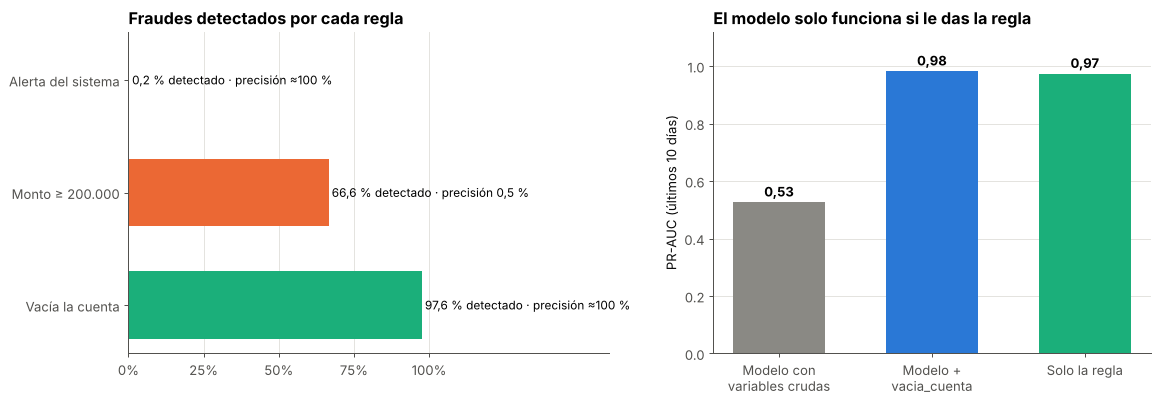

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
r = reglas.iloc[::-1]
cols = [VERDE, NARANJA, GRIS]
ax.barh(range(len(r)), r["Recall"], color=cols, height=0.6)
for i, (n, row) in enumerate(r.iterrows()):
    prec = "≈100 %" if row["Precisión"] > 0.99 else f"{es(row['Precisión'] * 100, 1)} %"
    ax.text(row["Recall"] + 0.01, i, f"{es(row['Recall'] * 100, 1)} % detectado · precisión {prec}", va="center", fontsize=9.5)
ax.set_yticks(range(len(r)), ["Vacía la cuenta", "Monto ≥ 200.000", "Alerta del sistema"])
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1.6); ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_title("Fraudes detectados por cada regla")
ax.set_axisbelow(True); ax.grid(axis="y", visible=False)

ax = axes[1]
m = modelos.iloc[[0, 1, 2]]
ax.bar(range(3), m["PR-AUC"], color=[GRIS, AZUL, VERDE], width=0.6)
for i, v in enumerate(m["PR-AUC"]):
    ax.text(i, v + 0.02, es(v, 2), ha="center", fontweight="bold")
ax.set_xticks(range(3), ["Modelo con\nvariables crudas", "Modelo +\nvacia_cuenta", "Solo la regla"])
ax.set_ylim(0, 1.12); ax.set_ylabel("PR-AUC (últimos 10 días)")
ax.set_title("El modelo solo funciona si le das la regla")
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar("03_fraude_reglas_vs_modelo")

**Lectura:** con las variables crudas, el modelo no descubre el patrón (PR-AUC ≈ 0,5): un árbol compara cada variable contra umbrales, y "monto **igual** al saldo" es una relación entre dos variables. Con `vacia_cuenta` llega a ~0,98, prácticamente lo mismo que la regla sola. La ingeniería de variables con criterio de negocio vale más que el algoritmo.

## 7. ¿Qué tan realista es PaySim?
Dos patrones más confirman que el fraude sigue reglas del simulador:

In [13]:
por_dia = pd.DataFrame({"legitimas": d[y == 0].groupby("dia")["peso"].sum(),
                        "fraudes": d[y == 1].groupby("dia").size()}).fillna(0)
por_hora = d[tc].groupby("hora").apply(lambda g: g["isFraud"].sum() / g["peso"].sum())
noche = d[tc & (d["hora"] < 6)]; dia_h = d[tc & d["hora"].between(9, 20)]
tasa_noche = noche["isFraud"].sum() / noche["peso"].sum()
tasa_dia = dia_h["isFraud"].sum() / dia_h["peso"].sum()
print(f"Legítimas por día: {es(por_dia['legitimas'].iloc[:17].mean())} (días 1-17) → {es(por_dia['legitimas'].iloc[17:].mean())} (días 18-30)")
print(f"Fraudes por día: {es(por_dia['fraudes'].mean())} (desv. {es(por_dia['fraudes'].std())}), estables todo el mes")
print(f"Tasa de fraude en transferencias y retiros: {tasa_noche:.1%} entre 0 y 5 h vs. {tasa_dia:.2%} entre 9 y 20 h")

Legítimas por día: 351.947 (días 1-17) → 26.525 (días 18-30)
Fraudes por día: 265 (desv. 23), estables todo el mes
Tasa de fraude en transferencias y retiros: 18.9% entre 0 y 5 h vs. 0.16% entre 9 y 20 h


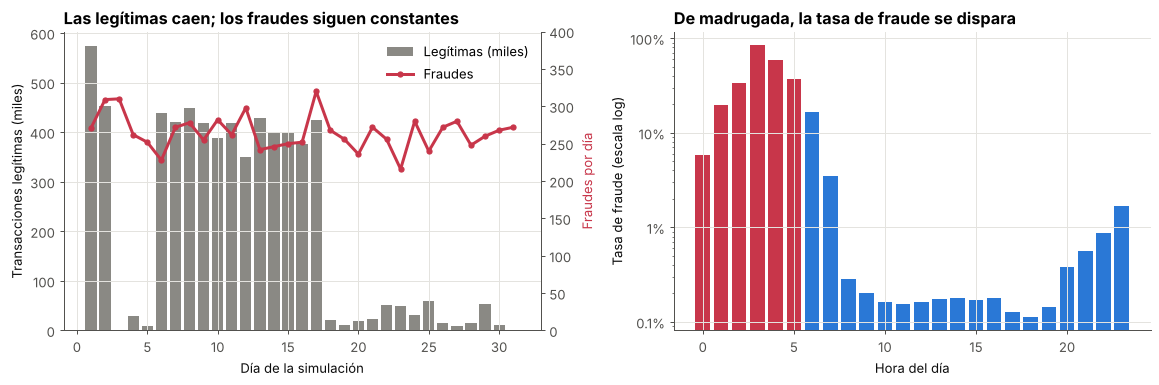

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.bar(por_dia.index + 1, por_dia["legitimas"] / 1000, color=GRIS, width=0.8, label="Legítimas (miles)")
ax2 = ax.twinx()
ax2.plot(por_dia.index + 1, por_dia["fraudes"], color=ROJO, lw=2.4, marker="o", ms=4, label="Fraudes")
ax2.set_ylim(0, 400); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax2.set_ylabel("Fraudes por día", color=ROJO)
ax.set_xlabel("Día de la simulación"); ax.set_ylabel("Transacciones legítimas (miles)")
ax.set_title("Las legítimas caen; los fraudes siguen constantes")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")

ax = axes[1]
ax.bar(por_hora.index, por_hora.values, color=[ROJO if h < 6 else AZUL for h in por_hora.index], width=0.8)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}" if v < 0.01 else f"{v:.0%}"))
ax.set_xlabel("Hora del día"); ax.set_ylabel("Tasa de fraude (escala log)")
ax.set_title("De madrugada, la tasa de fraude se dispara")
plt.tight_layout()
guardar("04_realismo_simulador")

- Desde el día 18, las transacciones legítimas caen a una fracción mientras los fraudes siguen en ~265 por día: la prevalencia del fraude cambia artificialmente. Un modelo evaluado con un split aleatorio no lo notaría.
- El fraude se reparte parejo en las 24 horas, pero la actividad legítima casi desaparece de madrugada: entre 0 y 5 h, cerca de **1 de cada 5** transferencias o retiros es fraude.

Son señales útiles para un ejercicio, pero muestran por qué los resultados de PaySim (muchos notebooks públicos reportan ROC-AUC ≈ 0,99) no se trasladan directamente a datos reales.

## 8. Antes y después

In [15]:
vac = reglas.loc["Vacía la cuenta (monto = saldo previo)"]
antes_despues = pd.DataFrame({
    "Versión 1": ["Predecir la 'discrepancia de conciliación'", f"Regresión lineal · R² {es(r2_v1, 2)}",
                  "Random Forest · 88 % de exactitud", "Riesgo de conciliación", "No analizado",
                  "Split aleatorio", "Dashboard sobre un objetivo determinístico"],
    "Versión 2": ["Auditar el objetivo antes de modelarlo", "Fórmula exacta: máx(0, monto − saldo) · R² 1,00",
                  "Regla de una línea · 100 %", "Transacciones sin saldo suficiente (artefacto del simulador)",
                  f"Regla 'vacía la cuenta': {vac['Recall']:.1%} de los fraudes (sistema: 0,2 %)",
                  "Validación temporal (últimos 10 días)", "Reglas y límites del dataset documentados"],
}, index=["Enfoque", "Discrepancia", "Categorías de riesgo", "Qué mide la discrepancia", "Fraude", "Validación", "Entregable"])
antes_despues.to_csv(REP / "antes_despues.csv")
antes_despues

,Versión 1,Versión 2
Enfoque,Predecir la 'discrepancia de conciliación',Auditar el objetivo antes de modelarlo
Discrepancia,"Regresión lineal · R² 0,97","Fórmula exacta: máx(0, monto − saldo) · R² 1,00"
Categorías de riesgo,Random Forest · 88 % de exactitud,Regla de una línea · 100 %
Qué mide la discrepancia,Riesgo de conciliación,Transacciones sin saldo suficiente (artefacto del simulador)
Fraude,No analizado,"Regla 'vacía la cuenta': 97.6% de los fraudes (sistema: 0,2 %)"
Validación,Split aleatorio,Validación temporal (últimos 10 días)
Entregable,Dashboard sobre un objetivo determinístico,Reglas y límites del dataset documentados


## 9. Conclusiones

1. **Un R² de 0,96 con variables simples era una señal de alerta, no un logro.** La discrepancia de la v1 es exactamente `máx(0, monto − saldo previo)`. Cuando el objetivo se construye con las mismas columnas que se usan para predecirlo, el modelo aprende aritmética.
2. **Antes de modelar, verificar si el objetivo es una regla.** Las categorías de riesgo de la v1 se reproducen al 100 % con una línea de código; el Random Forest (88 %) solo se acercaba. Y un 13 % de las transacciones era riesgo "Medio" por un centavo de redondeo.
3. **La discrepancia sí dice algo:** el 73 % de las salidas se ejecuta sin saldo suficiente. En datos reales sería un hallazgo de control para reportar; en PaySim revela que sus saldos no sirven para estudiar conciliación.
4. **El riesgo real es el fraude, y una regla de negocio le gana a la alerta existente:** "vacía la cuenta" detecta el 97,6 % de los fraudes sin falsas alarmas en la muestra, frente al 0,2 % de `isFlaggedFraud`.
5. **Un modelo no reemplaza el criterio:** sin la variable correcta, Gradient Boosting no encuentra el patrón; con ella, iguala a la regla.

**Limitaciones:** PaySim es sintético y sus patrones de fraude siguen reglas del simulador; las tasas a escala real se estiman con una muestra del 2 % de las transacciones legítimas.

**Lección personal:** el resultado más alto de mis proyectos era el que más necesitaba ser cuestionado.